In [1]:
from pathlib import Path
from datasets import load_dataset

DATA_DIR = Path("weapon VLM dataset")

dataset = load_dataset(
    "json",
    data_files={
        "train": str(DATA_DIR / "train.json"),
        "validation": str(DATA_DIR / "valid.json"),
        "test": str(DATA_DIR / "test.json"),
    },
)


c:\Users\User\anaconda3\envs\VLM_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig
from peft import LoraConfig, get_peft_model

model_id = "Qwen/Qwen2-VL-2B-Instruct"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    model_id,
    quantization_config=bnb_config,
    device_map="auto"
)

processor = AutoProcessor.from_pretrained(model_id)

lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    target_modules=["qkv", "proj"],
    lora_dropout=0.05,
    task_type="CAUSAL_LM"
)

model = get_peft_model(model, lora_config)

W0501 23:43:27.282000 6472 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels
Loading weights:   0%|          | 1/729 [00:00<04:16,  2.84it/s]c:\Users\User\anaconda3\envs\VLM_env\lib\site-packages\bitsandbytes\backends\cuda\ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)
Loading weights: 100%|██████████| 729/729 [00:03<00:00, 201.90it/s]


In [3]:
from PIL import Image


def resolve_image_path(image_path):
    candidate = Path(image_path)
    if candidate.is_file():
        return candidate

    dataset_candidate = DATA_DIR / candidate
    if dataset_candidate.is_file():
        return dataset_candidate

    basename_candidate = DATA_DIR / candidate.name
    if basename_candidate.is_file():
        return basename_candidate

    for split_name in ("train", "valid", "test"):
        split_candidate = DATA_DIR / split_name / "images" / candidate.name
        if split_candidate.is_file():
            return split_candidate

    raise FileNotFoundError(f"Could not resolve image path: {image_path}")


SYSTEM_PROMPT = "<|im_start|>system\nYou are a helpful assistant.<|im_end|>\n"
ASSISTANT_PREFIX = "<|im_start|>assistant\n"
ASSISTANT_SUFFIX = "<|im_end|>"


def build_prompt_and_images(example, add_generation_prompt):
    messages = example["messages"]
    user_message = next(message for message in messages if message["role"] == "user")
    assistant_message = next((message for message in messages if message["role"] == "assistant"), None)

    image_paths = []
    text_parts = []
    for content_item in user_message["content"]:
        if content_item["type"] == "image":
            image_paths.append(resolve_image_path(content_item["image"]))
        elif content_item["type"] == "text":
            text_parts.append(content_item["text"])

    image_tokens = "".join("<|vision_start|><|image_pad|><|vision_end|>" for _ in image_paths)
    user_text = "".join(text_parts)
    prompt = SYSTEM_PROMPT + f"<|im_start|>user\n{image_tokens}{user_text}<|im_end|>\n"

    images = [Image.open(image_path).convert("RGB") for image_path in image_paths]

    if add_generation_prompt:
        return prompt + ASSISTANT_PREFIX, images

    assistant_text = "".join(
        content_item["text"]
        for content_item in (assistant_message["content"] if assistant_message is not None else [])
        if content_item.get("type") == "text"
    )
    return prompt + ASSISTANT_PREFIX + assistant_text + ASSISTANT_SUFFIX, images


def preprocess(example):
    return example


In [4]:
import torch

def collate_fn(batch):
    prompt_texts = []
    full_texts = []
    images = []

    for example in batch:
        prompt_text, example_images = build_prompt_and_images(example, add_generation_prompt=True)
        full_text, _ = build_prompt_and_images(example, add_generation_prompt=False)

        prompt_texts.append(prompt_text)
        full_texts.append(full_text)
        images.append(example_images)

    # Tokenize full sequence (prompt + assistant response) for model inputs
    tokenized_full = processor(
        text=full_texts,
        images=images,
        return_tensors="pt",
        padding=True
    )

    # Tokenize only the prompt part to determine which tokens to ignore in the loss
    tokenized_prompt = processor(
        text=prompt_texts,
        images=images,
        return_tensors="pt",
        padding=True
    )

    labels = tokenized_full["input_ids"].clone()

    # Mask prompt tokens so loss is computed only over the assistant response
    prompt_mask_lengths = tokenized_prompt["attention_mask"].sum(dim=1)
    for i, plen in enumerate(prompt_mask_lengths.tolist()):
        if plen > 0:
            labels[i, : int(plen)] = -100

    tokenized_full["labels"] = labels

    return tokenized_full

In [ ]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./qwen_vl_model",
    per_device_train_batch_size=1,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    dataloader_num_workers=0,
    num_train_epochs=3,
    learning_rate=5e-5,
    warmup_steps=200,
    weight_decay=0.01,
    fp16=True,
    logging_steps=50,
    eval_strategy="steps",
    eval_steps=200,
    save_strategy="steps",
    save_steps=200,
    save_total_limit=2,
    remove_unused_columns=False,
    label_names=["labels"],
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    max_grad_norm=1.0,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset["train"],
    eval_dataset=dataset["validation"],
    data_collator=collate_fn
)

trainer.train()


Step,Training Loss,Validation Loss
200,7.318252,7.308817
400,7.225539,7.219868
600,7.210954,7.205901
800,7.204916,7.199113
1000,7.195825,7.191561
1200,7.195235,7.189143
1400,7.192735,7.187259
1600,7.187005,7.182615
1800,7.185487,7.180819
2000,7.181779,7.178953


TrainOutput(global_step=2250, training_loss=7.356861673990886, metrics={'train_runtime': 92745.2543, 'train_samples_per_second': 0.194, 'train_steps_per_second': 0.024, 'total_flos': 1.2685775424934733e+17, 'train_loss': 7.356861673990886, 'epoch': 10.0})

In [6]:
model.save_pretrained("./qwen_vl_model")
processor.save_pretrained("./qwen_vl_model")

['./qwen_vl_model\\processor_config.json']

In [7]:
def generate_answer(sample):
    text, images = build_prompt_and_images(sample, add_generation_prompt=True)

    inputs = processor(text=text, images=images, return_tensors="pt").to(model.device)

    output = model.generate(**inputs, max_new_tokens=100)

    return processor.decode(output[0], skip_special_tokens=True)

In [8]:
def classify(text):
    text = text.lower()
    if "false" in text or "not a weapon" in text:
        return 0
    elif "weapon" in text or "gun" in text or "knife" in text:
        return 1
    return -1

In [ ]:
import re
import sys
import subprocess
from importlib.util import find_spec


def ensure_package(package_name):
    if find_spec(package_name) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package_name])


ensure_package("pycocoevalcap")
ensure_package("nltk")

from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.rouge.rouge import Rouge
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.meteor.meteor import Meteor
from pycocoevalcap.spice.spice import Spice
from nltk.translate.meteor_score import meteor_score


def extract_assistant_text(decoded_text):
    parts = re.split(r"\bassistant\b", decoded_text, flags=re.IGNORECASE)
    cleaned = parts[-1] if len(parts) > 1 else decoded_text
    return cleaned.strip()


def get_ground_truth_text(sample):
    assistant_message = next((m for m in sample["messages"] if m["role"] == "assistant"), None)
    if assistant_message is None:
        return ""

    return " ".join(
        part["text"]
        for part in assistant_message["content"]
        if part.get("type") == "text"
    ).strip()


# Set to an integer for quick checks, or None to evaluate all test samples.
sample_limit = None

if sample_limit is None:
    eval_samples = dataset["test"]
else:
    eval_samples = dataset["test"].select(range(min(sample_limit, len(dataset["test"]))))

gts = {}
res = {}
meteor_pairs = []

for idx, sample in enumerate(eval_samples):
    pred_raw = generate_answer(sample)
    pred_text = extract_assistant_text(pred_raw)
    gt_text = get_ground_truth_text(sample)

    if gt_text:
        gts[idx] = [gt_text]
        res[idx] = [pred_text]
        meteor_pairs.append((gt_text, pred_text))

print(f"Evaluating {len(gts)} test samples")

metric_results = {}

# BLEU / ROUGE / CIDEr / SPICE via COCO caption evaluators
scorers = [
    ("BLEU", Bleu(4)),
    ("ROUGE", Rouge()),
    ("CIDEr", Cider()),
    ("SPICE", Spice()),
]

for metric_name, scorer in scorers:
    try:
        score, _ = scorer.compute_score(gts, res)

        if metric_name == "BLEU":
            for n, value in enumerate(score, start=1):
                metric_results[f"BLEU-{n}"] = value
        else:
            metric_results[metric_name] = score
    except Exception as exc:
        metric_results[metric_name] = f"unavailable ({exc})"

# METEOR: try COCO implementation first, then NLTK fallback
try:
    meteor_score_value, _ = Meteor().compute_score(gts, res)
    metric_results["METEOR"] = meteor_score_value
except Exception:
    meteor_values = []
    for gt_text, pred_text in meteor_pairs:
        gt_tokens = gt_text.split()
        pred_tokens = pred_text.split()
        meteor_values.append(meteor_score([gt_tokens], pred_tokens))

    metric_results["METEOR"] = sum(meteor_values) / len(meteor_values) if meteor_values else 0.0

for name, value in metric_results.items():
    print(f"{name}: {value}")

c:\Users\User\anaconda3\envs\VLM_env\lib\site-packages\bitsandbytes\backends\cuda\ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


Evaluating 1685 test samples
{'testlen': 13480, 'reflen': 13480, 'guess': [13480, 11795, 10110, 8425], 'correct': [13480, 11795, 10110, 8425]}
ratio: 0.9999999999999258


Test Sample #0: Cam5-From09-24-18To09-26-43-Guns_x264_Segment_0_x264_frame_100_jpg.rf.13ff938fd2bd3d339810888e43ab0a28.jpg


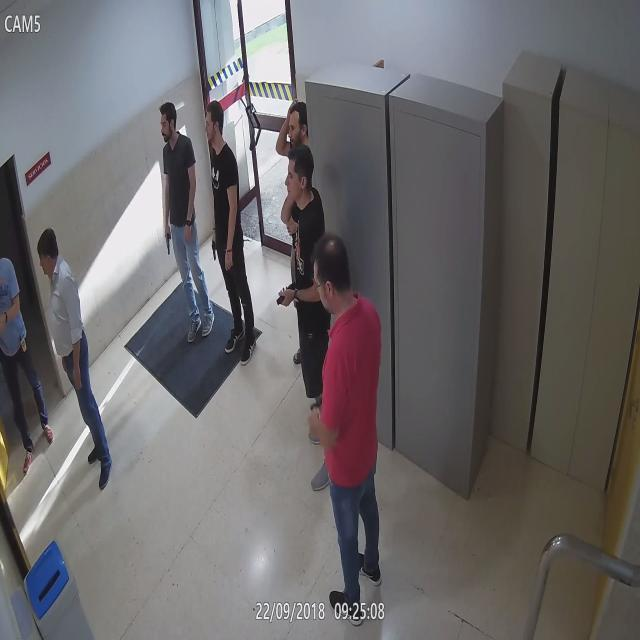

c:\Users\User\anaconda3\envs\VLM_env\lib\site-packages\bitsandbytes\backends\cuda\ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)



Model output:
system
You are a helpful assistant.
user
The detected object is at <box>(164,224,173,259)</box>. Is this a weapon or a false alarm?
assistant
Yes the object is identified as a weapon.

Ground truth:
Yes the object is identified as a weapon.


In [ ]:
from PIL import Image
from IPython.display import display

sample_idx = 0
sample = dataset["test"][sample_idx]

user_message = next(message for message in sample["messages"] if message["role"] == "user")
image_item = next(item for item in user_message["content"] if item["type"] == "image")
image_path = resolve_image_path(image_item["image"])
image = Image.open(image_path).convert("RGB")

print(f"Test Sample #{sample_idx}: {image_path.name}")
display(image)

pred_text = generate_answer(sample)
print("\nModel output:")
print(pred_text)

assistant_message = next((m for m in sample["messages"] if m["role"] == "assistant"), None)
if assistant_message is not None:
    gt_text = " ".join(
        part["text"] for part in assistant_message["content"] if part["type"] == "text"
    )
    print("\nGround truth:")
    print(gt_text)

In [8]:
from transformers import TrainingArguments, Trainer

smoke_args = TrainingArguments(
    output_dir="./qwen_vl_model_smoke_300",
    per_device_train_batch_size=1,
    gradient_accumulation_steps=1,
    dataloader_num_workers=0,
    max_steps=300,
    learning_rate=5e-5,
    fp16=True,
    logging_steps=1,
    eval_strategy="no",
    save_strategy="no",
    remove_unused_columns=False,
    label_names=["labels"],
    max_grad_norm=1.0,
    report_to="none",
)

smoke_trainer = Trainer(
    model=model,
    args=smoke_args,
    train_dataset=dataset["train"],
    data_collator=collate_fn,
)

smoke_output = smoke_trainer.train()

loss_points = [entry["loss"] for entry in smoke_trainer.state.log_history if "loss" in entry]
print("Smoke training steps:", len(loss_points))
print("Loss points:", loss_points)
if loss_points:
    print("First loss:", loss_points[0])
    print("Last loss:", loss_points[-1])
    print("Delta (last - first):", loss_points[-1] - loss_points[0])

smoke_output

Step,Training Loss
1,2.283523
2,2.179708
3,2.172612
4,2.331305
5,2.091113
6,2.405236
7,2.151519
8,2.785487
9,2.072056
10,2.110800


Smoke training steps: 300
Loss points: [2.2835230827331543, 2.1797075271606445, 2.172612190246582, 2.3313045501708984, 2.091113328933716, 2.405236005783081, 2.1515190601348877, 2.7854866981506348, 2.072056293487549, 2.110800266265869, 1.9414558410644531, 2.0137863159179688, 1.8650764226913452, 1.9227962493896484, 1.8212398290634155, 1.8958995342254639, 1.934502363204956, 1.756105661392212, 2.0860466957092285, 1.926723837852478, 1.7451355457305908, 1.9653904438018799, 1.7386201620101929, 1.6373487710952759, 1.7509616613388062, 1.7624518871307373, 1.6420905590057373, 1.760820984840393, 2.4269328117370605, 1.5737411975860596, 2.549163341522217, 1.7215633392333984, 1.5850392580032349, 1.5951788425445557, 1.524043321609497, 1.4552557468414307, 1.602993369102478, 1.4803564548492432, 2.3769631385803223, 1.5279672145843506, 1.5139291286468506, 1.431442379951477, 1.715981125831604, 1.479867696762085, 1.432025671005249, 1.5236049890518188, 2.4555203914642334, 2.1668317317962646, 1.38596832752227

TrainOutput(global_step=300, training_loss=0.5181477608790738, metrics={'train_runtime': 171.3463, 'train_samples_per_second': 1.751, 'train_steps_per_second': 1.751, 'total_flos': 2116962892322304.0, 'train_loss': 0.5181477608790738, 'epoch': 0.1669449081803005})

In [9]:
if loss_points:
    mid_idx = len(loss_points) // 2
    print('Loss count:', len(loss_points))
    print('First loss:', loss_points[0])
    print('Middle loss:', loss_points[mid_idx])
    print('Last loss:', loss_points[-1])
    print('Min loss:', min(loss_points))
    print('Max loss:', max(loss_points))
    print('Delta (last - first):', loss_points[-1] - loss_points[0])
    print('Delta (min - first):', min(loss_points) - loss_points[0])
else:
    print('No loss points recorded')

Loss count: 300
First loss: 2.2835230827331543
Middle loss: 0.0020109612960368395
Last loss: 0.0007959208451211452
Min loss: 0.00023556570522487164
Max loss: 2.7854866981506348
Delta (last - first): -2.282727161888033
Delta (min - first): -2.2832875170279294


### Smoke Run Note
The 300-step smoke run completed successfully after masking prompt tokens in the collator.

Observed training loss dropped from about 2.28 to 0.0008, which confirms the training loop is now updating and the model can fit the small smoke slice.

Because the smoke run is intentionally tiny and highly repeated, this should be treated as a pipeline check, not evidence of generalization.

In [11]:
from transformers import TrainingArguments, Trainer
from torch.utils.data import DataLoader

validation_loader = DataLoader(
    dataset["validation"],
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn,
)

model.eval()
validation_losses = []

with torch.no_grad():
    for batch in validation_loader:
        batch = {key: value.to(model.device) for key, value in batch.items()}
        outputs = model(**batch)
        validation_losses.append(outputs.loss.item())

mean_validation_loss = sum(validation_losses) / len(validation_losses) if validation_losses else float("nan")
print("Validation loss batches:", len(validation_losses))
print("Validation losses:", validation_losses)
print("Mean validation loss:", mean_validation_loss)

Validation loss batches: 515
Validation losses: [0.001132441684603691, 0.0009141245973296463, 0.0005161313456483185, 0.0006041488959454, 0.0004951194277964532, 0.000587643007747829, 0.3882032036781311, 0.0005278803291730583, 0.0006734657217748463, 0.0006312300101853907, 0.0012553893029689789, 0.0006875891704112291, 0.0008353799348697066, 0.0005114264786243439, 0.0005720063927583396, 0.0007315207039937377, 0.0006118979072198272, 0.0006371337221935391, 0.0004784131015185267, 0.000437950249761343, 0.0005223870393820107, 0.0011332060676068068, 0.0007616250077262521, 0.0005357146146707237, 0.001129440381191671, 0.0004995072958990932, 0.0005251164548099041, 0.0007662071730010211, 0.0005191910313442349, 0.0010372918331995606, 0.0004741510783787817, 0.0006356659578159451, 0.0007966287666931748, 0.0007148096337914467, 0.0006694904295727611, 0.0008325010421685874, 0.0010299388086423278, 0.0005654475535266101, 0.0005600692820735276, 0.0004038319457322359, 0.0004243592848069966, 0.0004139741940889

In [12]:
if validation_losses:
    print('Validation batch count:', len(validation_losses))
    print('Validation first loss:', validation_losses[0])
    print('Validation last loss:', validation_losses[-1])
    print('Validation min loss:', min(validation_losses))
    print('Validation max loss:', max(validation_losses))
    print('Validation mean loss:', mean_validation_loss)
else:
    print('No validation losses recorded')

Validation batch count: 515
Validation first loss: 0.001132441684603691
Validation last loss: 0.34063276648521423
Validation min loss: 0.00038233460509218276
Validation max loss: 1.5053983926773071
Validation mean loss: 0.04156995569807884
